# E1 — ASOS 기상 특징 추가 통합 Isolation Forest / E0 비교

**목표:** E0과 완전히 동일한 입력 행·학습 표본·모델 설정을 유지하고 기상 특징 세 가지(기온, 습도, 현지기압)만 추가해 E1을 학습합니다.

- Python 3.10.20 호환. 필요 패키지: `pandas`, `numpy`, `scikit-learn`, `matplotlib`, `joblib`.
- E0/E1 각 모델의 이상 점수 **절대값은 직접 비교하지 않습니다**. 동일 Test 행의 경보 변화, 상위 이상 순위 일치, 분포 및 시계열 사례를 비교합니다.
- 정답 고장 레이블이 없으므로 경보 비율은 오탐률이 아닙니다. E1 결과가 개선되었다고 단정하지 않습니다.
- E1은 과거 ASOS 관측자료를 사후 보간한 **오프라인 실험**입니다. 미래 관측값을 사용한 보간 결과는 실시간 배포 평가로 해석하지 않습니다.


## 0. 설정 및 입력 확인

In [1]:
from pathlib import Path
import json, platform, sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler

DATA_DIR = Path('clean_output')
if not DATA_DIR.is_dir() and Path('/mnt/data/clean_output').is_dir():
    DATA_DIR = Path('/mnt/data/clean_output')
E0_DIR = Path('e0_output')
if not (E0_DIR / 'e0_metadata.json').exists() and Path('/mnt/data/e0_output/e0_metadata.json').exists():
    E0_DIR = Path('/mnt/data/e0_output')
OUT_DIR = Path('e1_output')
OUT_DIR.mkdir(parents=True, exist_ok=True)
FILES = {s: DATA_DIR / f'06_common_{s}.csv' for s in ['train','validation','test']}
E0_META_FILE = E0_DIR / 'e0_metadata.json'
E0_TEST_FILE = E0_DIR / '02_test_scored.csv'
E0_VAL_FILE = E0_DIR / '02_validation_scored.csv'
for path in [*FILES.values(), E0_META_FILE, E0_TEST_FILE, E0_VAL_FILE]:
    if not path.is_file():
        raise FileNotFoundError(f'필수 파일 없음: {path.resolve()}')
E0_FEATURES = ['rate_output', 'energy_ratio', 'power_ratio_diff', 'ratio_ma_60min']
WEATHER_FEATURES = ['asos__기온(°C)', 'asos__습도(%)', 'asos__현지기압(hPa)']
FEATURES = E0_FEATURES + WEATHER_FEATURES
meta0 = json.loads(E0_META_FILE.read_text(encoding='utf-8'))
if meta0['features_ordered'] != E0_FEATURES:
    raise ValueError('E0 특징 순서가 예상과 다릅니다. E0 노트북의 metadata 확인 필요')
if not meta0['balance_plants']:
    raise ValueError('E0은 발전소 균형 학습이 아닙니다. E1의 학습 표본 정책을 일치시키세요.')
SEED = int(meta0['seed'])
Q = float(meta0['threshold_quantile'])
print('Python', sys.version.split()[0], 'sklearn', sklearn.__version__)
print('E0 metadata:', E0_META_FILE.resolve())


Python 3.10.20 sklearn 1.7.2
E0 metadata: D:\KKW\_Repository\VSCode\github\CBNU.Master.1yr.intelIoT\termproj\llm_suggest\e0_output\e0_metadata.json


## 1. 입력 데이터 및 동질성 검증

In [2]:
data = {}
needed = set(FEATURES) | {'source_plant','source_row','timestamp','split'}
for s, path in FILES.items():
    df = pd.read_csv(path, encoding='utf-8-sig', low_memory=False)
    absent = needed.difference(df.columns)
    if absent:
        raise ValueError(f'{s} 필수 컬럼 없음: {sorted(absent)}')
    if not df['split'].astype(str).eq(s).all():
        raise ValueError(f'{s} 분할 컬럼 불일치')
    if df.duplicated(['source_plant','source_row']).any():
        raise ValueError(f'{s} 고유 원본 키 중복')
    for f in FEATURES:
        df[f] = pd.to_numeric(df[f], errors='coerce')
    invalid = ~np.isfinite(df[FEATURES].to_numpy(dtype=float)).all(axis=1)
    if invalid.any():
        raise ValueError(f'{s}: E1 특징 결측/비유한 행 {int(invalid.sum())}개. E0과 같은 표본 비교를 위해 무단 삭제하지 않습니다.')
    df['timestamp'] = pd.to_datetime(df['timestamp'], errors='raise')
    data[s] = df

# E0 저장 레코드가 정확히 같은지, 키뿐 아니라 E0 입력 특성까지 확인
old = {}
for s, file in [('test',E0_TEST_FILE),('validation',E0_VAL_FILE)]:
    df = pd.read_csv(file, encoding='utf-8-sig', low_memory=False)
    key = ['source_plant','source_row']
    if df.duplicated(key).any():
        raise ValueError(f'E0 {s} 결과에 중복 키 존재')
    merged = data[s][key+E0_FEATURES].merge(df[key+E0_FEATURES+['anomaly_score','is_alert']], on=key, suffixes=('_e1','_e0'), how='outer', indicator=True, validate='one_to_one')
    if not merged['_merge'].eq('both').all() or len(merged) != len(data[s]):
        raise ValueError(f'E0과 E1의 {s} 표본이 다릅니다')
    for f in E0_FEATURES:
        a,b = merged[f+'_e1'].to_numpy(float), merged[f+'_e0'].to_numpy(float)
        if not np.allclose(a,b,rtol=1e-9,atol=1e-9):
            raise ValueError(f'{s}: E0/E1 입력 {f} 값 불일치')
    old[s] = df[key+['anomaly_score','is_alert']].rename(columns={'anomaly_score':'e0_score','is_alert':'e0_alert'})
summary = pd.concat([v.groupby('source_plant').size().rename('rows').reset_index().assign(split=k) for k,v in data.items()],ignore_index=True)
summary.to_csv(OUT_DIR/'01_input_summary.csv', index=False,encoding='utf-8-sig')
print(summary.to_string(index=False))
print('E0/E1 validation/test 원본 행 및 E0 특징 동질성 검사 완료')


source_plant   rows      split
           A 121909      train
           B  56571      train
           A  26124 validation
           B  12123 validation
           A  26124       test
           B  12123       test
E0/E1 validation/test 원본 행 및 E0 특징 동질성 검사 완료


## 2. E0과 동일한 학습 행 추출 · E1 모델 학습

In [3]:
groups = data['train'].groupby('source_plant', sort=True)
counts = groups.size()
if len(counts) != 2:
    raise ValueError(f'기준 발전소 2개가 아닙니다: {counts.to_dict()}')
n_each = int(counts.min())
fit_df = pd.concat([g.sample(n=n_each, random_state=SEED).copy() for _,g in groups], ignore_index=True)
fit_counts = {str(k):int(v) for k,v in fit_df.groupby('source_plant').size().items()}
if fit_counts != {str(k):int(v) for k,v in meta0['fit_counts'].items()}:
    raise ValueError('E0 학습 발전소별 표본 수와 다릅니다')
model = Pipeline([
    ('scale', RobustScaler()),
    ('iforest', IsolationForest(
        n_estimators=int(meta0['n_estimators']),
        max_samples=int(meta0['max_samples']),
        contamination='auto', random_state=SEED,n_jobs=-1,
    )),
])
model.fit(fit_df[FEATURES].to_numpy(float))
print('E1 train rows:', len(fit_df), fit_counts)


E1 train rows: 113142 {'A': 56571, 'B': 56571}


## 3. Validation 임계값 설정 및 공통 Test 추론

In [4]:
scored = {}
for s, df in data.items():
    x=df[FEATURES].to_numpy(float)
    z=df.copy()
    z['e1_score']=-model.score_samples(x)
    scored[s]=z
threshold1=float(scored['validation']['e1_score'].quantile(Q))
for s, z in scored.items():
    z['e1_alert']=(z['e1_score']>=threshold1)
    z['e1_threshold']=threshold1
    if s in old:
        z=z.merge(old[s],on=['source_plant','source_row'],how='left',validate='one_to_one')
        if z['e0_alert'].isna().any():
            raise ValueError(f'E0 결과 누락: {s}')
        z['e0_alert']=z['e0_alert'].astype(bool)
    scored[s]=z
    z.to_csv(OUT_DIR/f'02_{s}_scored.csv', index=False,encoding='utf-8-sig')
joblib.dump(model, OUT_DIR/'e1_weather_iforest.joblib')
meta1 = {
 'experiment':'E1','model':'IsolationForest','features_ordered':FEATURES,
 'weather_features':WEATHER_FEATURES,'seed':SEED,
 'n_estimators':int(meta0['n_estimators']),'max_samples':int(meta0['max_samples']),
 'fit_counts':fit_counts,'e1_threshold':threshold1,'e0_threshold':float(meta0['threshold']),
 'threshold_quantile':Q,'threshold_policy':'validation quantile',
 'score_direction':'-score_samples; higher means more unusual',
 'weather_data_mode':'historical offline, interpolation may use future data',
 'python_version':platform.python_version(),'sklearn_version':sklearn.__version__,
 'label_status':'unlabeled; detection accuracy and real false-positive rate unavailable',
}
(OUT_DIR/'e1_metadata.json').write_text(json.dumps(meta1,ensure_ascii=False,indent=2),encoding='utf-8')
print('E0 threshold:',meta0['threshold'],'| E1 threshold:',threshold1)
print('주의: 서로 다른 모델의 점수 절대값 및 임계값 크기는 성능 우열의 근거가 아닙니다.')


E0 threshold: 0.6081341434748425 | E1 threshold: 0.5529089552785883
주의: 서로 다른 모델의 점수 절대값 및 임계값 크기는 성능 우열의 근거가 아닙니다.


## 4. 발전소별 경보 변화 및 일치도

In [5]:
rows=[]
for s in ['validation','test']:
    df=scored[s]
    for p,g in df.groupby('source_plant'):
        a=g['e0_alert'].to_numpy(bool)
        b=g['e1_alert'].to_numpy(bool)
        intersection=int((a&b).sum())
        union=int((a|b).sum())
        rows.append({
            'split':s,'plant':p,'rows':len(g),
            'e0_alerts':int(a.sum()),'e1_alerts':int(b.sum()),
            'e0_alert_rate':float(a.mean()),'e1_alert_rate':float(b.mean()),
            'both_alerts':intersection,'e0_only':int((a&~b).sum()),
            'e1_only':int((~a&b).sum()),
            'jaccard_of_alert_sets':intersection/union if union else np.nan,
            'agreement_all_rows':float((a==b).mean()),
            'e0_top_score_p99':float(g['e0_score'].quantile(.99)),
            'e1_top_score_p99':float(g['e1_score'].quantile(.99)),
        })
metrics=pd.DataFrame(rows)
metrics.to_csv(OUT_DIR/'03_e0_e1_comparison.csv', index=False, encoding='utf-8-sig')
print(metrics[['split','plant','rows','e0_alerts','e1_alerts','e0_only','e1_only','jaccard_of_alert_sets','agreement_all_rows']].to_string(index=False))


     split plant  rows  e0_alerts  e1_alerts  e0_only  e1_only  jaccard_of_alert_sets  agreement_all_rows
validation     A 26124        498        501      131      134               0.580696            0.989856
validation     B 12123        267        264       38       35               0.758278            0.993978
      test     A 26124        632        610      175      153               0.582166            0.987444
      test     B 12123        222        180       66       24               0.634146            0.992576


## 5. Test 이상 후보의 변동 사례

같은 Test 원본 행 중 **E0에서만 경보 / E1에서만 경보 / 둘 다 경보**를 각각 확인합니다. 순위의 변화는 확인할 수 있지만, 어느 모델이 맞는지는 고장 레이블이나 추가 검증 없이 결정할 수 없습니다.


In [6]:
test=scored['test'].copy()
test['change_type'] = np.select([
    test['e0_alert'] & test['e1_alert'],
    test['e0_alert'] & ~test['e1_alert'],
    ~test['e0_alert'] & test['e1_alert'],
], ['both','e0_only','e1_only'],default='neither')
cols=['source_plant','source_row','timestamp','change_type','e0_score','e1_score',
      'rate_output','energy_ratio','power_ratio_diff','ratio_ma_60min',*WEATHER_FEATURES]
examples=[]
for (plant, kind), g in test[test.change_type != 'neither'].groupby(['source_plant','change_type']):
    examples.append(g.sort_values('e1_score',ascending=False).head(30)[cols])
examples_df=pd.concat(examples,ignore_index=True) if examples else pd.DataFrame(columns=cols)
examples_df.to_csv(OUT_DIR/'04_alert_changed_examples.csv',index=False,encoding='utf-8-sig')
print(test.groupby(['source_plant','change_type']).size().to_string())


source_plant  change_type
A             both             457
              e0_only          175
              e1_only          153
              neither        25339
B             both             156
              e0_only           66
              e1_only           24
              neither        11877


## 6. 그림 및 최종 안내

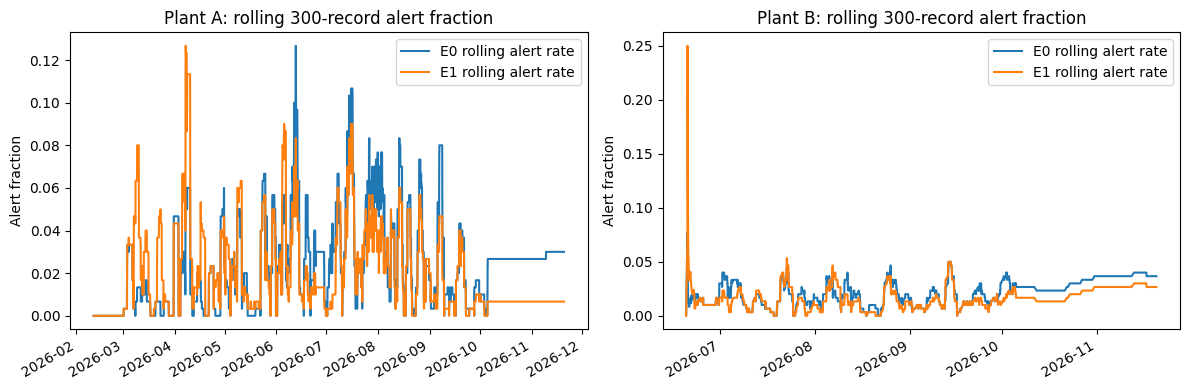

결과 디렉터리: D:\KKW\_Repository\VSCode\github\CBNU.Master.1yr.intelIoT\termproj\llm_suggest\e1_output
저장 파일:
01_input_summary.csv
02_test_scored.csv
02_train_scored.csv
02_validation_scored.csv
03_e0_e1_comparison.csv
04_alert_changed_examples.csv
05_alert_comparison.png
e1_metadata.json
e1_weather_iforest.joblib
결론 유의: 실측 고장 레이블이 없으므로 경보율·일치도가 높아도 이상 탐지 정확도 향상으로 결론 낼 수 없습니다.


In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for i,(plant,g) in enumerate(test.groupby('source_plant')):
    g=g.sort_values('timestamp')
    ax=axes[i]
    ax.plot(g['timestamp'],g['e0_alert'].astype(int).rolling(300,min_periods=1).mean(),label='E0 rolling alert rate')
    ax.plot(g['timestamp'],g['e1_alert'].astype(int).rolling(300,min_periods=1).mean(),label='E1 rolling alert rate')
    ax.set_title(f'Plant {plant}: rolling 300-record alert fraction')
    ax.set_ylabel('Alert fraction')
    ax.legend(loc='best')
fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(OUT_DIR/'05_alert_comparison.png',dpi=140)
plt.show()
print('결과 디렉터리:', OUT_DIR.resolve())
print('저장 파일:')
print('\n'.join(sorted(x.name for x in OUT_DIR.iterdir())))
print('결론 유의: 실측 고장 레이블이 없으므로 경보율·일치도가 높아도 이상 탐지 정확도 향상으로 결론 낼 수 없습니다.')


## 7. 결과 해석 원칙 및 후속 조치

1. `03_e0_e1_comparison.csv`에서 두 발전소의 경보율과 경보 집합 Jaccard 일치도를 비교합니다. **점수 값 자체는 다른 특징 차원에서 학습된 모델 간 비교할 수 없습니다.**
2. E1 기상 특징은 기존 인버터 특징과 함께 정상 기상변동을 더 잘 반영할 *가능성*이 있지만, 기상 관측소 대표성 및 ASOS 시간 보간의 영향도 받습니다.
3. 실험 E0/E1 중 어느 쪽이 우수한지 판단하려면 고장 이력 또는 **독립적인 통제 이상 주입 테스트**와 정상 구간의 확인이 필요합니다.
4. OPC UA 10개 가상 발전소에는 하나의 선택 모델을 동일하게 적용하되, 각 설비의 시계열 상태는 별도로 유지해야 합니다.
5. 실시간 적용 시 E1과 달리 미래 기상값이 없는 환경에서의 결측 보정 정책을 새로 검증해야 합니다.
